# Belt Conveyor: geared drive — sensor vs camera

**Question:** can a temperature sensor and an infrared camera each tell if a conveyor's drive gearbox is worn?

| | Sensor | Camera |
|---|---|---|
| Data | CORA T1 temperature | CORA infrared camera |
| Classes | healthy vs gear-worn | healthy vs gear-worn |
| Tested on | 16 runs, one speed held out at a time | the same 16 runs |

CORA is one lab motor/gearbox rig, used as a stand-in for a **geared** conveyor drive (not belts or idlers). Both branches use the same 16 runs (4 wear levels × 4 speeds) but are trained separately. All the code is in this notebook; run it from top to bottom.

## Step 1 — Setup

In [1]:
import json
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.io import loadmat
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support

# Find the project folder (the one that contains Raw_Data/ and Results/)
here = Path.cwd().resolve()
ROOT = next(p for p in (here, *here.parents) if (p / "Results").is_dir() and (p / "Raw_Data").is_dir())
RAW, RESULTS = ROOT / "Raw_Data", ROOT / "Results"


def score(actual, predicted, classes):
    """Accuracy, macro precision/recall/F1 and the confusion matrix."""
    p, r, f, _ = precision_recall_fscore_support(actual, predicted, labels=classes, zero_division=0)
    return {"accuracy": round(accuracy_score(actual, predicted), 4), "macro_precision": round(p.mean(), 4),
            "macro_recall": round(r.mean(), 4), "macro_f1": round(f.mean(), 4),
            "matrix": confusion_matrix(actual, predicted, labels=classes)}


def predict_recordings(model, x, y, recording):
    """One prediction per recording: average the model's probabilities over all its windows/frames."""
    actual, predicted = [], []
    for name in sorted(set(recording)):
        rows = recording == name
        actual.append(y[rows][0])
        predicted.append(model.classes_[np.argmax(model.predict_proba(x[rows]).mean(axis=0))])
    return actual, predicted


def forest():
    return RandomForestClassifier(n_estimators=250, max_features="sqrt", class_weight="balanced_subsample",
                                  min_samples_leaf=2, random_state=42, n_jobs=-1)


def show_matrices(panels, classes):
    fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 3.8))
    for ax, (title, m) in zip(np.atleast_1d(axes), panels):
        ax.imshow(m, cmap="Blues", vmin=0)
        ax.set_xticks(range(len(classes)), classes, rotation=30)
        ax.set_yticks(range(len(classes)), classes)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
        ax.set_title(title, fontsize=10)
        for i in range(len(classes)):
            for j in range(len(classes)):
                ax.text(j, i, m[i, j], ha="center", va="center", color="white" if m[i, j] > m.max() / 2 else "black")
    fig.tight_layout()
    plt.show()


def table(rows):
    return pd.DataFrame({name: {k: v for k, v in s.items() if k != "matrix"} for name, s in rows.items()}).T


print("Project folder found:", ROOT.name)

Project folder found: capstone-week4


## Step 2 — Load both kinds of data

Run names look like `W50_F15_S`: wear level (H = healthy, W25/W50/W75 = worn), then speed (F5, F15, F50, F60).

- **Sensor:** eight short samples (6,000 readings each) of T1 temperature per run.
- **Camera:** 450 infrared frames per run.

In [2]:
RUNS = [f"{c}_{s}_S" for c in ("H", "W25", "W50", "W75") for s in ("F5", "F15", "F50", "F60")]
y = np.array([0 if r.startswith("H_") else 1 for r in RUNS])        # 0 = healthy, 1 = gear-worn
speed = np.array([r.split("_")[1] for r in RUNS])
t1 = np.load(ROOT / "Processed_Data" / "cora_gear_wear" / "t1_bounded_samples.npz")
print(len(RUNS), "runs:", sum(y == 0), "healthy,", sum(y == 1), "worn")

16 runs: 4 healthy, 12 worn


## Step 3 — Turn each run into one row of numbers

**Sensor:** average temperature level, spread and trend across the eight samples.
**Camera (OpenCV):** brightness, hot-spot share and edge strength of each frame, averaged over all 450 frames.

In [3]:
def sensor_features(v):
    means = v.mean(axis=1)
    return [means.mean(), means.std(), np.median(means), means.min(), means.max(),
            np.polyfit(np.arange(8), means, 1)[0],                       # trend over the run
            v.std(axis=1).mean(), np.mean(np.percentile(v, 90, axis=1) - np.percentile(v, 10, axis=1))]


def infrared_features(path):
    frames = loadmat(path, variable_names=["imagenes_celda"])["imagenes_celda"]
    rows = []
    for frame in frames.flat:
        gray = cv2.cvtColor(cv2.resize(frame, (128, 128)), cv2.COLOR_RGB2GRAY).astype(np.float32)
        center = gray[32:96, 32:96]
        rows.append([gray.mean(), gray.std(), np.percentile(gray, 90), np.percentile(gray, 99),
                     np.mean(gray >= 220),                                 # share of hot pixels
                     center.mean() - gray.mean(), center.std(),
                     np.mean(np.abs(np.diff(gray, axis=1)))])              # edge strength
    rows = np.asarray(rows)
    return np.concatenate([rows.mean(axis=0), rows.std(axis=0)])


sensor_x = np.array([sensor_features(t1[r]) for r in RUNS])
camera_x = np.array([infrared_features(RAW / "cora_gear_wear" / f"{r}.mat") for r in RUNS])
print("Sensor features:", sensor_x.shape, "| Camera features:", camera_x.shape)

Sensor features: (16, 8) | Camera features: (16, 16)


## Step 4 — Train and test both

Four rounds: each round hides one speed (4 runs) and trains on the other 12 runs. Every run is predicted once by a model that never saw it.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def leave_one_speed_out(x):
    model_pred, guess_pred = np.zeros(16, int), np.zeros(16, int)
    for s in ("F5", "F15", "F50", "F60"):
        test, train = speed == s, speed != s
        model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", solver="liblinear",
                                                                   max_iter=1000, random_state=42))
        model_pred[test] = model.fit(x[train], y[train]).predict(x[test])
        guess_pred[test] = DummyClassifier(strategy="most_frequent").fit(x[train], y[train]).predict(x[test])
    return score(y, model_pred, [0, 1]), score(y, guess_pred, [0, 1])


sensor, guess = leave_one_speed_out(sensor_x)
camera, _ = leave_one_speed_out(camera_x)
display(table({"Sensor: T1 temperature": sensor, "Camera: infrared": camera, "Always guess 'worn'": guess}))

,accuracy,macro_precision,macro_recall,macro_f1
Sensor: T1 temperature,0.625,0.5667,0.5833,0.5636
Camera: infrared,0.500,0.4333,0.4167,0.4182
Always guess 'worn',0.750,0.3750,0.5000,0.4286


## Step 5 — Compare sensor and camera

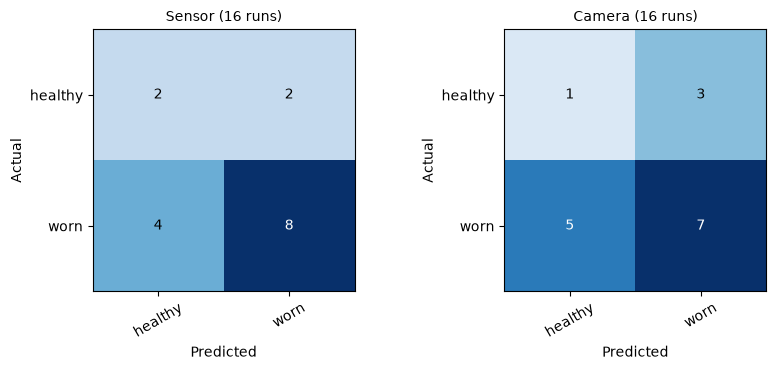

In [5]:
show_matrices([("Sensor (16 runs)", sensor["matrix"]), ("Camera (16 runs)", camera["matrix"])], ["healthy", "worn"])

## Step 6 — Check against the saved results

In [6]:
saved = {}
rows = []
for label, mine, path in [
    ('Sensor', sensor, 'belt_conveyor_cora.json/sensor/model'),
    ('Camera', camera, 'belt_conveyor_cora.json/infrared/model'),
    ('Always guess', guess, 'belt_conveyor_cora.json/sensor/most_frequent_control'),
]:
    file, *keys = path.split('/')
    node = json.loads((RESULTS / file).read_text(encoding='utf-8'))
    for key in keys:
        node = node[key]
    same = all(round(node[k], 4) == mine[k] for k in ('accuracy', 'macro_precision', 'macro_recall', 'macro_f1'))
    rows.append({'result': label, 'this notebook': mine['accuracy'], 'saved result': round(node['accuracy'], 4),
                 'same': 'yes' if same else 'NO'})
display(pd.DataFrame(rows).set_index('result'))

,this notebook,saved result,same
result,,,
Sensor,0.625,0.625,yes
Camera,0.500,0.500,yes
Always guess,0.750,0.750,yes


## What this means

- **Weak result, reported honestly.** Sensor 0.625 and camera 0.500 are both **below 0.750**, the score from always guessing "worn" (12 of 16 runs are worn).
- The camera spots only 1 of the 4 healthy runs.
- **Why:** only 16 runs from one rig, one run per wear level and speed, and only short temperature samples.
- **Limits:** a lab gearbox, not a mining conveyor; it classifies the present condition, not when to repair.

**Data (CC BY 4.0):** CORA v2.1, DOI 10.34810/DATA2500.